# Xác minh dữ liệu

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip -q install pyarrow scikit-learn matplotlib

from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import json
import re
import time
import hashlib
import sklearn

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

INTERIM = ROOT / "data/interim"
SHARDS = INTERIM / "embeddings_shards"
MANIFESTS = INTERIM / "shard_manifests"

INDEX = INTERIM / "embedding_shard_index.csv"
REGISTRY = INTERIM / "post_registry.csv"
REGISTRY_MANIFEST = INTERIM / "post_registry_manifest.json"
ACCEPTANCE = INTERIM / "full_post_acceptance.json"
SCOPE_CONFIG = INTERIM / "selected_scope.json"

OUT = ROOT / "reports/results/nd3_task4b"
SEED = 42

checks = {
    "project_root": ROOT.is_dir(),
    "interim": INTERIM.is_dir(),
    "embeddings_shards": SHARDS.is_dir(),
    "shard_manifests": MANIFESTS.is_dir(),
    "embedding_shard_index": INDEX.is_file(),
    "post_registry": REGISTRY.is_file(),
    "post_registry_manifest": REGISTRY_MANIFEST.is_file(),
    "full_post_acceptance": ACCEPTANCE.is_file(),
    "selected_scope": SCOPE_CONFIG.is_file()
}

print("========== ND3 TASK 4B PREFLIGHT ==========")

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} | {name}")

assert all(checks.values()), "FAIL | Missing input files"

OUT.mkdir(parents=True, exist_ok=True)

print("\nPASS | Project input structure verified")
print("Output:", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
========== ND3 TASK 4B PREFLIGHT ==========
PASS | project_root
PASS | interim
PASS | embeddings_shards
PASS | shard_manifests
PASS | embedding_shard_index
PASS | post_registry
PASS | post_registry_manifest
PASS | full_post_acceptance
PASS | selected_scope

PASS | Project input structure verified
Output: /content/drive/MyDrive/NarrativeCast/reports/results/nd3_task4b


# KIểm tra 94 shards và đọc schema

In [ ]:
index = pd.read_csv(INDEX)

print("========== EMBEDDING INDEX ==========")
print("Index columns:", index.columns.tolist())
print("Index rows:", len(index))

assert {"shard", "rows", "file"}.issubset(index.columns)

index["shard"] = index["shard"].astype(int)
index["rows"] = index["rows"].astype(int)

assert index["shard"].is_unique
assert set(index["shard"]) == set(range(94))

# Dùng tên file từ index, bỏ đường dẫn cũ
index["resolved_path"] = index["file"].map(
    lambda p: str(SHARDS / Path(str(p)).name)
)

index["exists"] = index["resolved_path"].map(
    lambda p: Path(p).is_file()
)

missing = index.loc[~index["exists"]]

print("Expected shards:", len(index))
print("Existing shards:", index["exists"].sum())
print("Expected embeddings:", index["rows"].sum())

assert missing.empty, (
    "FAIL | Missing shards:\n"
    + missing.to_string(index=False)
)

assert int(index["rows"].sum()) == 751607

with np.load(
    index.sort_values("shard").iloc[0]["resolved_path"],
    allow_pickle=False
) as z:
    npz_schema = {
        k: {
            "shape": z[k].shape,
            "dtype": str(z[k].dtype)
        }
        for k in z.files
    }

print("\n========== NPZ SCHEMA ==========")
print(json.dumps(npz_schema, indent=2))

print("\n========== POST REGISTRY ==========")

registry_header = pd.read_csv(REGISTRY, nrows=5)

print("Registry columns:", registry_header.columns.tolist())
display(registry_header.head(3))

print("\nPASS | 94-shard inventory verified")

========== EMBEDDING INDEX ==========
Index columns: ['shard', 'file', 'rows', 'first_id', 'last_id']
Index rows: 94
Expected shards: 94
Existing shards: 94
Expected embeddings: 751607

========== NPZ SCHEMA ==========
{
  "vectors": {
    "shape": [
      8000,
      384
    ],
    "dtype": "float32"
  },
  "post_ids": {
    "shape": [
      8000
    ],
    "dtype": "<U36"
  },
  "is_valid": {
    "shape": [
      8000
    ],
    "dtype": "bool"
  },
  "metadata": {
    "shape": [
      1
    ],
    "dtype": "<U593"
  },
  "timestamps": {
    "shape": [
      8000
    ],
    "dtype": "<U20"
  }
}

========== POST REGISTRY ==========
Registry columns: ['post_id', 'content', 'publish_datetime_utc']


,post_id,content,publish_datetime_utc
0,0794186e-4a21-5f75-8fdd-52874f2fc50b,Enhanced network security controls: the real v...,2014-01-01 00:01:00+00:00
1,2150b5a8-2fce-5e04-a22a-782da5218956,10 Real Tech to watch in 2014,2014-01-01 00:03:41+00:00
2,30acc1d6-2c04-5a21-b2ef-58b90ab6f31b,Male Edge Usa,2014-01-01 00:03:43+00:00



PASS | 94-shard inventory verified


# Kiểm tra phạm vi nghiên cứu và nội dung POST

In [ ]:
print("========== SOURCE DATA AUDIT ==========")

with open(ACCEPTANCE, encoding="utf-8") as f:
    acceptance = json.load(f)

with open(REGISTRY_MANIFEST, encoding="utf-8") as f:
    registry_manifest = json.load(f)

with open(SCOPE_CONFIG, encoding="utf-8") as f:
    old_scope = json.load(f)

print("Embedding acceptance:")
print(json.dumps(acceptance, indent=2, ensure_ascii=False))

print("\nRegistry manifest:")
print(json.dumps(registry_manifest, indent=2, ensure_ascii=False))

print("\nExisting scope:")
print(json.dumps(old_scope, indent=2, ensure_ascii=False))

# Tìm dữ liệu sạch, không tải file vào RAM
candidates = [
    ROOT / "data/processed/reddit_technology_clean.parquet",
    ROOT / "data/interim/reddit_technology_clean.parquet",
    ROOT / "data/raw/reddit_technology_clean.parquet"
]

candidates += list(
    (ROOT / "data").rglob("reddit_technology_clean.parquet")
)

candidates = list(dict.fromkeys(candidates))
available = [p for p in candidates if p.is_file()]

print("\n========== CONTENT SOURCES ==========")

for p in available:
    print("FOUND:", p)

required = {
    "post_id",
    "content",
    "publish_datetime_utc",
    "interaction_type",
    "is_usable_text"
}

registry_columns = set(registry_header.columns)

if available:
    PARQUET = available[0]
    pf = pq.ParquetFile(PARQUET)

    assert required.issubset(pf.schema_arrow.names), (
        "FAIL | Parquet missing required columns"
    )
    SOURCE_MODE = "PARQUET"
    print("PASS | Parquet content source available")

elif required.issubset(registry_columns):
    PARQUET = None
    SOURCE_MODE = "REGISTRY"
    print("PASS | Registry has all required fields")

else:
    PARQUET = None
    SOURCE_MODE = None
    print("BLOCKED | No complete POST content source")

print("SOURCE_MODE:", SOURCE_MODE)

========== SOURCE DATA AUDIT ==========
Embedding acceptance:
{
  "status": "PASS",
  "run_hash": "e7480e1fd1620bc2",
  "model": "sentence-transformers/all-MiniLM-L6-v2",
  "embedding_dim": 384,
  "full_post_rows": 751607,
  "source_total_rows": 11597712,
  "months": 84,
  "source_fingerprint": "a469984900de94c4655be620b009363af15562d900212f01ea78560b7f72c5db",
  "comment_embedding_created": false,
  "scope_selected": false,
  "task": "ND3.4a full POST discovery evidence"
}

Registry manifest:
{
  "run_hash": "e7480e1fd1620bc2",
  "source_rows": 11597712,
  "post_rows": 751607,
  "unique_ids": 751607,
  "months": [
    "2014-01",
    "2014-02",
    "2014-03",
    "2014-04",
    "2014-05",
    "2014-06",
    "2014-07",
    "2014-08",
    "2014-09",
    "2014-10",
    "2014-11",
    "2014-12",
    "2015-01",
    "2015-02",
    "2015-03",
    "2015-04",
    "2015-05",
    "2015-06",
    "2015-07",
    "2015-08",
    "2015-09",
    "2015-10",
    "2015-11",
    "2015-12",
    "2016-01",
  

# Trích xuất tập POST cho Net Neutrality

In [ ]:
assert SOURCE_MODE is not None, (
    "FAIL | Resolve content source before continuing"
)

START = pd.Timestamp("2014-01-01", tz="UTC")
END = pd.Timestamp("2021-01-01", tz="UTC")

SCOPE_REGEX = (
    r"\b(?:"
    r"net[\s\-]?neutrality|"
    r"internet[\s\-]?neutrality|"
    r"network[\s\-]?neutrality|"
    r"paid[\s\-]?prioriti[sz]ation|"
    r"open[\s\-]?internet[\s\-]?order"
    r")\b"
)

PATTERN = re.compile(SCOPE_REGEX, re.IGNORECASE)

columns = [
    "post_id",
    "content",
    "publish_datetime_utc",
    "interaction_type",
    "is_usable_text"
]

frames = []
total_eligible = 0

def process_batch(df):
    global total_eligible

    dates = pd.to_datetime(
        df["publish_datetime_utc"],
        utc=True,
        errors="coerce"
    )

    eligible = (
        df["interaction_type"].astype(str).eq("POST")
        & df["is_usable_text"].astype(str)
            .str.lower().eq("true")
        & dates.ge(START)
        & dates.lt(END)
    )

    total_eligible += int(eligible.sum())

    sub = df.loc[eligible].copy()
    sub["publish_datetime_utc"] = dates.loc[eligible]

    matched = sub["content"].fillna("").str.contains(
        PATTERN,
        regex=True
    )

    return sub.loc[matched].copy()

if SOURCE_MODE == "PARQUET":
    for batch in pf.iter_batches(
        batch_size=100000,
        columns=columns
    ):
        part = process_batch(batch.to_pandas())
        if len(part):
            frames.append(part)

else:
    for chunk in pd.read_csv(
        REGISTRY,
        usecols=columns,
        chunksize=100000
    ):
        part = process_batch(chunk)
        if len(part):
            frames.append(part)

assert frames, "FAIL | No scope POST found"

scope = pd.concat(frames, ignore_index=True)

scope["post_id"] = scope["post_id"].astype(str)

assert not scope.empty
assert scope["post_id"].is_unique
assert scope["publish_datetime_utc"].notna().all()

scope.to_csv(
    OUT / "scope_posts.csv",
    index=False
)

print("========== SCOPE EXTRACTION ==========")
print("Eligible POSTs:", total_eligible)
print("Net Neutrality candidates:", len(scope))
print("Candidate fraction:", len(scope) / total_eligible)
print("First:", scope.publish_datetime_utc.min())
print("Last:", scope.publish_datetime_utc.max())

print("PASS | Candidate scope extracted")

========== SCOPE EXTRACTION ==========
Eligible POSTs: 751607
Net Neutrality candidates: 7096
Candidate fraction: 0.009441104194080152
First: 2014-01-06 21:40:29+00:00
Last: 2020-12-04 19:40:28+00:00
PASS | Candidate scope extracted


# Lấy embedding đúng theo post_id

In [ ]:
from sklearn.preprocessing import normalize

VECTOR_KEYS = ("embeddings", "vectors", "X")
ID_KEYS = ("post_ids", "post_id", "ids")

target_ids = set(scope["post_id"])

selected_ids = []
selected_vectors = []
seen = set()

def find_key(options, available):
    return next(
        (k for k in options if k in available),
        None
    )

for row in index.sort_values("shard").itertuples():
    path = Path(row.resolved_path)

    with np.load(path, allow_pickle=False) as z:
        vk = find_key(VECTOR_KEYS, z.files)
        ik = find_key(ID_KEYS, z.files)

        assert vk is not None, (
            f"FAIL | Unknown vector key: {path.name}: {z.files}"
        )
        assert ik is not None, (
            f"FAIL | Unknown ID key: {path.name}: {z.files}"
        )

        ids_part = z[ik].astype(str)
        vectors_part = z[vk]

        assert vectors_part.shape == (len(ids_part), 384)
        assert len(ids_part) == int(row.rows)

        mask = np.isin(ids_part, list(target_ids))

        ids_found = ids_part[mask].tolist()

        assert not (set(ids_found) & seen), (
            "FAIL | Duplicate embedding post_id"
        )
        seen.update(ids_found)

        if ids_found:
            selected_ids.extend(ids_found)
            selected_vectors.append(
                vectors_part[mask].astype(np.float32)
            )

    print(
        f"Shard {row.shard:02d}: {len(ids_found)} selected"
    )

assert selected_vectors, "FAIL | No matched embeddings"

X = np.vstack(selected_vectors)
X = normalize(X, norm="l2").astype(np.float32)

ids = np.asarray(selected_ids, dtype=str)

assert len(ids) == len(X)
assert len(set(ids)) == len(ids)
assert np.isfinite(X).all()

coverage = len(ids) / len(target_ids)

print("\n========== EMBEDDING JOIN ==========")
print("Candidate POSTs:", len(scope))
print("Matched embeddings:", len(ids))
print("Coverage:", coverage)
print("X shape:", X.shape)

assert coverage == 1.0, (
    "FAIL | Some candidate POSTs have no embeddings"
)

print("PASS | Embedding join complete")

Shard 00: 53 selected
Shard 01: 94 selected
Shard 02: 42 selected
Shard 03: 27 selected
Shard 04: 21 selected
Shard 05: 24 selected
Shard 06: 12 selected
Shard 07: 319 selected
Shard 08: 119 selected
Shard 09: 57 selected
Shard 10: 115 selected
Shard 11: 64 selected
Shard 12: 121 selected
Shard 13: 47 selected
Shard 14: 247 selected
Shard 15: 105 selected
Shard 16: 63 selected
Shard 17: 177 selected
Shard 18: 277 selected
Shard 19: 135 selected
Shard 20: 104 selected
Shard 21: 54 selected
Shard 22: 60 selected
Shard 23: 22 selected
Shard 24: 22 selected
Shard 25: 10 selected
Shard 26: 31 selected
Shard 27: 41 selected
Shard 28: 24 selected
Shard 29: 46 selected
Shard 30: 26 selected
Shard 31: 32 selected
Shard 32: 10 selected
Shard 33: 14 selected
Shard 34: 9 selected
Shard 35: 9 selected
Shard 36: 12 selected
Shard 37: 39 selected
Shard 38: 27 selected
Shard 39: 10 selected
Shard 40: 21 selected
Shard 41: 8 selected
Shard 42: 7 selected
Shard 43: 15 selected
Shard 44: 28 selected
Shar

# Thử nghiệm và so sánh số cụm

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

assert len(X) >= 100, "FAIL | Too few vectors"

rng = np.random.default_rng(SEED)
eval_idx = rng.choice(
    len(X),
    min(3000, len(X)),
    replace=False
)

K_VALUES = [
    k for k in [8, 12, 16, 24, 32]
    if k < len(X)
]

experiments = []
models = {}

for k in K_VALUES:
    t0 = time.perf_counter()

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=SEED,
        batch_size=2048,
        n_init=5,
        max_iter=200
    )

    labels = model.fit_predict(X)

    second = MiniBatchKMeans(
        n_clusters=k,
        random_state=SEED + 1,
        batch_size=2048,
        n_init=5,
        max_iter=200
    )

    labels_2 = second.fit_predict(X)

    sizes = np.bincount(labels, minlength=k)
    eval_labels = labels[eval_idx]

    if 1 < len(np.unique(eval_labels)) < len(eval_labels):
        silhouette = silhouette_score(
            X[eval_idx],
            eval_labels,
            metric="cosine"
        )
    else:
        silhouette = np.nan

    experiments.append({
        "k": k,
        "silhouette_cosine": silhouette,
        "stability_ari": adjusted_rand_score(
            labels[eval_idx],
            labels_2[eval_idx]
        ),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "largest_fraction": float(sizes.max() / len(X)),
        "runtime_seconds": round(
            time.perf_counter() - t0, 2
        )
    })

    models[k] = model

comparison = pd.DataFrame(experiments)
comparison.to_csv(
    OUT / "experiment_comparison.csv",
    index=False
)

display(comparison)
print("PASS | Configuration comparison completed")

,k,silhouette_cosine,stability_ari,smallest_cluster,largest_cluster,largest_fraction,runtime_seconds
0,8,0.041805,0.393586,272,1462,0.206032,4.22
1,12,0.035005,0.418597,289,958,0.135006,7.79
2,16,0.042233,0.371714,234,866,0.122041,2.29
3,24,0.049245,0.398661,48,782,0.110203,2.85
4,32,0.054893,0.381524,26,479,0.067503,7.00


PASS | Configuration comparison completed


# Chọn cấu hình và xuất Cluster ID

In [ ]:
valid = comparison.dropna(
    subset=["silhouette_cosine", "stability_ari"]
).copy()

assert not valid.empty

valid["score"] = (
    0.50 * valid["silhouette_cosine"].rank(ascending=False)
    + 0.35 * valid["stability_ari"].rank(ascending=False)
    + 0.15 * valid["largest_fraction"].rank(ascending=True)
)

valid = valid.sort_values(["score", "k"])

BEST_K = int(valid.iloc[0]["k"])
best_model = models[BEST_K]
labels = best_model.predict(X)

assignments = pd.DataFrame({
    "post_id": ids,
    "cluster_id": labels.astype(int)
})

assignments = assignments.merge(
    scope[["post_id", "publish_datetime_utc"]],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert len(assignments) == len(scope)
assert assignments.post_id.is_unique
assert assignments.cluster_id.nunique() == BEST_K
assert assignments.publish_datetime_utc.notna().all()

assignments.to_csv(
    OUT / "cluster_assignments.csv",
    index=False
)

print("Selected K:", BEST_K)
print("Assigned POSTs:", len(assignments))
print("PASS | Cluster assignments saved")

Selected K: 24
Assigned POSTs: 7096
PASS | Cluster assignments saved


# Thống kê, lấy ví dụ và trực quan hóa

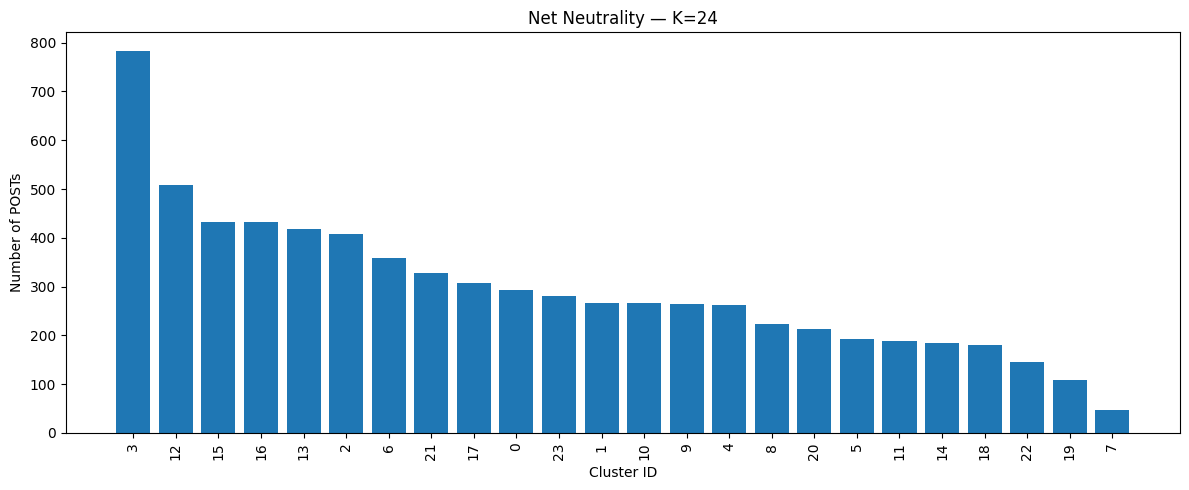

,cluster_id,cluster_size,first_post,last_post,fraction
3,3,782,2014-01-14 18:33:04+00:00,2020-11-25 14:21:13+00:00,0.110203
12,12,509,2014-01-14 23:53:44+00:00,2020-07-15 15:20:06+00:00,0.071731
15,15,432,2014-01-15 02:10:12+00:00,2020-04-02 21:19:11+00:00,0.060879
16,16,432,2014-02-03 21:13:11+00:00,2020-10-12 17:01:36+00:00,0.060879
13,13,419,2014-02-19 00:00:03+00:00,2020-06-11 13:54:19+00:00,0.059047
2,2,407,2014-01-15 01:06:29+00:00,2020-11-26 13:48:12+00:00,0.057356
6,6,359,2014-01-14 16:05:45+00:00,2020-12-03 14:28:20+00:00,0.050592
21,21,327,2014-01-14 20:40:46+00:00,2020-07-13 14:18:33+00:00,0.046082
17,17,308,2014-01-15 17:12:55+00:00,2020-03-02 15:34:23+00:00,0.043405
0,0,294,2014-01-14 22:56:57+00:00,2020-10-22 19:23:17+00:00,0.041432


,post_id,cluster_id,representative_rank,centroid_similarity,temporary_cluster_label,content,publish_datetime_utc
0,3209ab55-00bd-540d-ad9d-31ba2c24a169,0,1,0.884333,UNLABELED,Complaints about Net Neutrality Flooding the FCC,2014-05-12 13:04:43+00:00
1,e523a12a-b63b-56da-8c1b-eaab5eb1d7a0,0,2,0.871122,UNLABELED,The FCC's Flimsy Defense of Fake Net Neutrality,2014-05-01 05:10:05+00:00
2,b9ed2d89-46a7-5232-a982-afce8e0ca1bf,0,3,0.864930,UNLABELED,The FCC will now take your net neutrality comp...,2015-06-12 14:52:09+00:00
3,a25b314b-b7e1-57a2-9c7e-41bd88378a33,0,4,0.861290,UNLABELED,The FCC Has Rejected The First (Silly) Net Neu...,2015-10-07 15:46:46+00:00
4,769753e7-f8c4-552c-bea7-c418ce976841,0,5,0.860868,UNLABELED,The FCC Must Ignore the Silly ‘Net Neutrality’...,2014-05-20 10:29:17+00:00
5,d8a29ef8-d203-5750-98cc-7b0f8b6816cd,0,6,0.856961,UNLABELED,The FCC is now pretending to back down from it...,2014-05-12 13:38:15+00:00
6,86c3a850-458d-5224-86d8-a89b9afaffbf,0,7,0.856388,UNLABELED,How the FCC May Have Shot Itself in the Foot o...,2018-03-16 19:14:21+00:00
7,f26ad517-0567-5be4-a19b-049138c5f83b,0,8,0.856292,UNLABELED,Millions told the FCC they want net neutrality,2017-11-26 23:16:38+00:00
8,7b037b03-151d-583d-bbaa-c766bfd5a157,0,9,0.853634,UNLABELED,Verizon’s bizarre claim that the FCC isn’t kil...,2017-05-01 17:25:17+00:00
9,e5eb1233-793a-509f-b833-417d253ca086,0,10,0.852776,UNLABELED,The FCC Is Blocking a Law Enforcement Investig...,2017-12-16 16:42:49+00:00


PASS | Statistics and examples saved


In [ ]:
stats = (
    assignments.groupby("cluster_id")
    .agg(
        cluster_size=("post_id", "size"),
        first_post=("publish_datetime_utc", "min"),
        last_post=("publish_datetime_utc", "max")
    )
    .reset_index()
    .sort_values("cluster_size", ascending=False)
)

stats["fraction"] = stats.cluster_size / len(assignments)

stats.to_csv(
    OUT / "cluster_statistics.csv",
    index=False
)

centers = normalize(
    best_model.cluster_centers_.astype(np.float32)
)

example_rows = []

for cid in sorted(assignments.cluster_id.unique()):
    loc = np.flatnonzero(labels == cid)
    similarities = X[loc] @ centers[cid]

    chosen = np.argsort(-similarities)[:10]

    for rank, j in enumerate(chosen, start=1):
        pos = loc[j]
        example_rows.append({
            "post_id": ids[pos],
            "cluster_id": int(cid),
            "representative_rank": rank,
            "centroid_similarity": float(similarities[j]),
            "temporary_cluster_label": "UNLABELED"
        })

examples = pd.DataFrame(example_rows)

examples = examples.merge(
    scope[["post_id", "content", "publish_datetime_utc"]],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert examples.content.notna().all()

examples.to_csv(
    OUT / "cluster_examples.csv",
    index=False
)

plt.figure(figsize=(12, 5))
plt.bar(
    stats.cluster_id.astype(str),
    stats.cluster_size
)
plt.title(f"Net Neutrality — K={BEST_K}")
plt.xlabel("Cluster ID")
plt.ylabel("Number of POSTs")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(OUT / "cluster_sizes.png", dpi=180)
plt.show()

display(stats.head(15))
display(examples.head(20))

print("PASS | Statistics and examples saved")

# Lưu manifest

In [ ]:
manifest = {
    "task": "ND3.4b",
    "status": "PROVISIONAL",
    "run_id": "nd3_4b_post_2014_2020_v1",
    "source_mode": SOURCE_MODE,
    "source_path": str(
        PARQUET if PARQUET is not None else REGISTRY
    ),
    "embedding_directory": str(SHARDS),
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "embedding_dim": 384,
    "scope": {
        "interaction_type": "POST",
        "start": START.isoformat(),
        "end_exclusive": END.isoformat(),
        "regex": SCOPE_REGEX,
        "scope_post_count": len(scope),
        "scope_status": "CANDIDATE_NOT_GOLD"
    },
    "algorithm": "MiniBatchKMeans",
    "k_values": K_VALUES,
    "selected_k": BEST_K,
    "random_state": SEED,
    "n_init": 5,
    "batch_size": 2048,
    "max_iter": 200,
    "normalization": "L2",
    "selection": "weighted_rank_provisional",
    "assigned_post_count": len(assignments),
    "limitations": [
        "Keyword retrieval may omit relevant posts",
        "Clustering is retrospective over 2014-2020",
        "Clusters are not confirmed narratives",
        "Temporary cluster labels require review"
    ]
}

manifest_path = OUT / "experiment_manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

checks = {
    "scope_saved": (OUT / "scope_posts.csv").is_file(),
    "comparison_saved": (
        OUT / "experiment_comparison.csv"
    ).is_file(),
    "assignments_saved": (
        OUT / "cluster_assignments.csv"
    ).is_file(),
    "statistics_saved": (
        OUT / "cluster_statistics.csv"
    ).is_file(),
    "examples_saved": (
        OUT / "cluster_examples.csv"
    ).is_file(),
    "manifest_saved": manifest_path.is_file(),
    "full_coverage": len(assignments) == len(scope),
    "unique_post_ids": assignments.post_id.is_unique,
    "cluster_counts_match": stats.cluster_size.sum() == len(X),
    "all_examples_real": examples.content.notna().all()
}

print("========== TASK 4B TECHNICAL GATES ==========")

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} | {name}")

assert all(checks.values()), "FAIL | Technical gate"

print("\nTASK 4B: PROVISIONAL TECHNICAL PASS")
print("Scientific review and temporary labels still pending")

========== TASK 4B TECHNICAL GATES ==========
PASS | scope_saved
PASS | comparison_saved
PASS | assignments_saved
PASS | statistics_saved
PASS | examples_saved
PASS | manifest_saved
PASS | full_coverage
PASS | unique_post_ids
PASS | cluster_counts_match
PASS | all_examples_real

TASK 4B: PROVISIONAL TECHNICAL PASS
Scientific review and temporary labels still pending


# Lấy mẫu đa dạng để đặt nhãn cho từng cluster

In [ ]:
# CELL 10 — Cluster labeling evidence

sample_rows = []

for cid in sorted(np.unique(labels)):
    loc = np.flatnonzero(labels == cid)

    sim = X[loc] @ centers[cid]
    ordered = loc[np.argsort(-sim, kind="stable")]

    n = len(ordered)

    # Chia thành 3 vùng theo cosine similarity
    strata = {
        "CORE": ordered[:max(1, n // 3)],
        "MIDDLE": ordered[n // 3:2 * n // 3],
        "EDGE": ordered[2 * n // 3:]
    }

    for group, positions in strata.items():
        if len(positions) == 0:
            continue

        count = min(5, len(positions))

        # Lấy các vị trí trải đều trong từng vùng
        chosen = positions[
            np.linspace(
                0, len(positions) - 1,
                count, dtype=int
            )
        ]

        for pos in np.unique(chosen):
            sample_rows.append({
                "post_id": ids[pos],
                "cluster_id": int(cid),
                "sample_group": group,
                "centroid_similarity": float(
                    X[pos] @ centers[cid]
                )
            })

labeling_samples = pd.DataFrame(sample_rows)

labeling_samples = labeling_samples.merge(
    scope[
        ["post_id", "content", "publish_datetime_utc"]
    ],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert labeling_samples["content"].notna().all()
assert set(labeling_samples.cluster_id) == set(np.unique(labels))

labeling_samples.to_csv(
    OUT / "cluster_labeling_samples.csv",
    index=False
)

print("Total labeling samples:", len(labeling_samples))
print("Clusters covered:", labeling_samples.cluster_id.nunique())

display(
    labeling_samples.groupby(
        ["cluster_id", "sample_group"]
    ).size().unstack(fill_value=0)
)

print("PASS | Cluster labeling evidence generated")

Total labeling samples: 360
Clusters covered: 24


sample_group,CORE,EDGE,MIDDLE
cluster_id,,,
0,5,5,5
1,5,5,5
2,5,5,5
3,5,5,5
4,5,5,5
5,5,5,5
6,5,5,5
7,5,5,5
8,5,5,5


PASS | Cluster labeling evidence generated


In [ ]:
# CELL 11 — Prepare temporary cluster labels

cluster_label_review = stats[
    ["cluster_id", "cluster_size", "fraction"]
].copy()

cluster_label_review["temporary_label_en"] = ""
cluster_label_review["dominant_topic"] = ""
cluster_label_review["possible_frame"] = ""
cluster_label_review["label_confidence"] = ""
cluster_label_review["evidence_post_ids"] = ""
cluster_label_review["notes"] = ""
cluster_label_review["review_status"] = "PENDING"

# Hai nhãn sơ bộ dựa trên những ví dụ đã xem
cluster_label_review.loc[
    cluster_label_review.cluster_id == 0,
    "temporary_label_en"
] = "FCC Proceedings and Net Neutrality Disputes"

cluster_label_review.loc[
    cluster_label_review.cluster_id == 1,
    "temporary_label_en"
] = "Net Neutrality Court Rulings"

cluster_label_review.to_csv(
    OUT / "cluster_temporary_labels.csv",
    index=False
)

display(cluster_label_review)

print("PASS | Temporary labeling worksheet created")
print("NOTE | All labels still require review")

,cluster_id,cluster_size,fraction,temporary_label_en,dominant_topic,possible_frame,label_confidence,evidence_post_ids,notes,review_status
3,3,782,0.110203,,,,,,,PENDING
12,12,509,0.071731,,,,,,,PENDING
15,15,432,0.060879,,,,,,,PENDING
16,16,432,0.060879,,,,,,,PENDING
13,13,419,0.059047,,,,,,,PENDING
2,2,407,0.057356,,,,,,,PENDING
6,6,359,0.050592,,,,,,,PENDING
21,21,327,0.046082,,,,,,,PENDING
17,17,308,0.043405,,,,,,,PENDING
0,0,294,0.041432,FCC Proceedings and Net Neutrality Disputes,,,,,,PENDING


PASS | Temporary labeling worksheet created
NOTE | All labels still require review


In [ ]:
import joblib

model_path = OUT / "selected_clustering_model.joblib"
joblib.dump(best_model, model_path)

reloaded_model = joblib.load(model_path)

predicted = reloaded_model.predict(X)

assert np.array_equal(
    predicted,
    assignments["cluster_id"].to_numpy()
)

print("PASS | Model saved and predictions verified")


PASS | Model saved and predictions verified


# Kiểm tra độ ổn định với 5 random seeds

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations
from sklearn.preprocessing import normalize
import numpy as np
import pandas as pd
import time

print("========== CELL 12 | STABILITY AUDIT ==========")

SEEDS = [11, 23, 42, 71, 101]
AUDIT_K = [12, 24, 32]

assert X.ndim == 2 and X.shape[1] == 384
assert len(ids) == len(X)
assert np.isfinite(X).all()

X = np.asarray(X, dtype=np.float32)

stability_rows = []
seed_labels = {}
seed_models = {}

for k in AUDIT_K:
    runs = {}

    for seed in SEEDS:
        t0 = time.perf_counter()

        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=5,
            max_iter=200
        )

        pred = model.fit_predict(X)

        runs[seed] = pred
        seed_models[(k, seed)] = model
        seed_labels[(k, seed)] = pred

        sizes = np.bincount(pred, minlength=k)

        stability_rows.append({
            "k": k,
            "seed": seed,
            "n_clusters_found": len(np.unique(pred)),
            "smallest_cluster": int(sizes.min()),
            "largest_cluster": int(sizes.max()),
            "largest_fraction": float(sizes.max() / len(X)),
            "inertia": float(model.inertia_),
            "runtime_seconds": round(
                time.perf_counter() - t0, 3
            )
        })

    ari_values = [
        adjusted_rand_score(runs[a], runs[b])
        for a, b in combinations(SEEDS, 2)
    ]

    print(
        f"K={k} | mean ARI={np.mean(ari_values):.4f}"
        f" | min={np.min(ari_values):.4f}"
        f" | max={np.max(ari_values):.4f}"
    )

    if k == AUDIT_K[0]:
        pairwise_rows = []

    for (a, b), score in zip(
        combinations(SEEDS, 2), ari_values
    ):
        pairwise_rows.append({
            "k": k,
            "seed_a": a,
            "seed_b": b,
            "ari": float(score)
        })

seed_runs = pd.DataFrame(stability_rows)
pairwise = pd.DataFrame(pairwise_rows)

stability_summary = (
    pairwise.groupby("k")
    .agg(
        mean_ari=("ari", "mean"),
        min_ari=("ari", "min"),
        std_ari=("ari", "std"),
        max_ari=("ari", "max")
    )
    .reset_index()
)

seed_runs.to_csv(
    OUT / "stability_seed_runs.csv",
    index=False
)

pairwise.to_csv(
    OUT / "stability_pairwise_ari.csv",
    index=False
)

stability_summary.to_csv(
    OUT / "stability_summary.csv",
    index=False
)

display(stability_summary)

assert len(seed_runs) == 15
assert len(pairwise) == 30
assert pairwise["ari"].between(-1, 1).all()
assert seed_runs["n_clusters_found"].eq(
    seed_runs["k"]
).all()

print("\nPASS | Multi-seed stability audit completed")

========== CELL 12 | STABILITY AUDIT ==========
K=12 | mean ARI=0.4017 | min=0.3592 | max=0.4934
K=24 | mean ARI=0.3982 | min=0.3702 | max=0.4249
K=32 | mean ARI=0.3952 | min=0.3450 | max=0.4625


,k,mean_ari,min_ari,std_ari,max_ari
0,12,0.401737,0.359230,0.043143,0.493367
1,24,0.398232,0.370245,0.020153,0.424931
2,32,0.395213,0.344950,0.042188,0.462501



PASS | Multi-seed stability audit completed


In [ ]:
import re
import unicodedata

print("========== CELL 13 | DUPLICATE AUDIT ==========")

def normalize_content(text):
    text = unicodedata.normalize(
        "NFKC", str(text)
    )
    text = text.casefold()
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

content_map = scope[
    ["post_id", "content"]
].copy()

content_map["post_id"] = content_map["post_id"].astype(str)

audit = assignments.merge(
    content_map,
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert audit["content"].notna().all()

audit["normalized_content"] = (
    audit["content"].map(normalize_content)
)

audit["duplicate_group_size"] = (
    audit.groupby("normalized_content")["post_id"]
    .transform("size")
)

audit["is_duplicate_content"] = (
    audit["duplicate_group_size"] > 1
)

# Đánh dấu bản sao thứ hai trở đi
audit = audit.sort_values(
    ["normalized_content", "post_id"]
).copy()

audit["is_extra_copy"] = audit.duplicated(
    "normalized_content",
    keep="first"
)

duplicate_summary = (
    audit.groupby("cluster_id")
    .agg(
        cluster_size=("post_id", "size"),
        duplicate_members=("is_duplicate_content", "sum"),
        extra_copies=("is_extra_copy", "sum"),
        unique_normalized_texts=("normalized_content", "nunique")
    )
    .reset_index()
)

duplicate_summary["duplicate_member_fraction"] = (
    duplicate_summary["duplicate_members"]
    / duplicate_summary["cluster_size"]
)

duplicate_summary.to_csv(
    OUT / "duplicate_audit_by_cluster.csv",
    index=False
)

audit.loc[audit["is_duplicate_content"], [
    "post_id",
    "cluster_id",
    "content",
    "duplicate_group_size"
]].to_csv(
    OUT / "duplicate_post_examples.csv",
    index=False
)

print("Total POSTs:", len(audit))
print(
    "Unique normalized texts:",
    audit.normalized_content.nunique()
)
print(
    "Additional copies:",
    int(audit.is_extra_copy.sum())
)
print(
    "Duplicate member fraction:",
    round(audit.is_duplicate_content.mean(), 4)
)

display(
    duplicate_summary.sort_values(
        "duplicate_member_fraction",
        ascending=False
    ).head(15)
)

assert len(audit) == len(assignments)
assert duplicate_summary.cluster_size.sum() == len(audit)

print("\nPASS | Exact normalized duplicate audit")

========== CELL 13 | DUPLICATE AUDIT ==========
Total POSTs: 7096
Unique normalized texts: 7032
Additional copies: 64
Duplicate member fraction: 0.0175


,cluster_id,cluster_size,duplicate_members,extra_copies,unique_normalized_texts,duplicate_member_fraction
1,1,267,12,6,261,0.044944
18,18,180,6,3,177,0.033333
6,6,359,11,6,353,0.030641
22,22,145,4,2,143,0.027586
3,3,782,20,11,771,0.025575
21,21,327,8,4,323,0.024465
20,20,214,5,3,212,0.023364
14,14,185,4,2,183,0.021622
15,15,432,9,5,428,0.020833
19,19,109,2,1,108,0.018349



PASS | Exact normalized duplicate audit


In [ ]:
print("========== CELL 14 | SCOPE COVERAGE AUDIT ==========")

# Các dấu hiệu mở rộng, chỉ để tìm bài có khả năng bị bỏ sót
EXPANSION_REGEX = (
    r"\b(?:"
    r"title[\s\-]?ii|"
    r"broadband[\s\-]+reclassification|"
    r"isp[\s\-]+throttling|"
    r"internet[\s\-]+fast[\s\-]?lanes|"
    r"broadband[\s\-]+fast[\s\-]?lanes|"
    r"fcc[\s\-]+repeal|"
    r"open[\s\-]+internet[\s\-]+rules"
    r")\b"
)

extension_pattern = re.compile(
    EXPANSION_REGEX, re.IGNORECASE
)

existing_ids = set(scope["post_id"].astype(str))

near_miss_parts = []

def get_near_miss(df):
    dates = pd.to_datetime(
        df["publish_datetime_utc"],
        utc=True,
        errors="coerce"
    )

    eligible = (
        df["interaction_type"].astype(str).eq("POST")
        & df["is_usable_text"].astype(str)
            .str.lower().eq("true")
        & dates.ge(START)
        & dates.lt(END)
    )

    candidates = df.loc[eligible].copy()

    candidate_mask = (
        candidates["content"].fillna("")
        .str.contains(extension_pattern, regex=True)
    )

    candidates = candidates.loc[candidate_mask]

    return candidates.loc[
        ~candidates["post_id"].astype(str).isin(existing_ids)
    ].copy()

if SOURCE_MODE == "PARQUET":
    for batch in pq.ParquetFile(PARQUET).iter_batches(
        batch_size=100000,
        columns=columns
    ):
        part = get_near_miss(batch.to_pandas())
        if not part.empty:
            near_miss_parts.append(part)
else:
    for chunk in pd.read_csv(
        REGISTRY,
        usecols=columns,
        chunksize=100000
    ):
        part = get_near_miss(chunk)
        if not part.empty:
            near_miss_parts.append(part)

if near_miss_parts:
    near_misses = pd.concat(
        near_miss_parts, ignore_index=True
    )
else:
    near_misses = pd.DataFrame(columns=columns)

near_misses["post_id"] = near_misses["post_id"].astype(str)

assert near_misses["post_id"].is_unique
assert not set(near_misses["post_id"]) & existing_ids

# Lấy mẫu tái lập để người đánh giá xem nội dung
near_miss_sample = near_misses.sample(
    n=min(100, len(near_misses)),
    random_state=SEED
).copy()

near_miss_sample["relevance_label"] = "PENDING"
near_miss_sample["review_reason"] = ""

near_miss_sample.to_csv(
    OUT / "scope_near_miss_review.csv",
    index=False
)

print("Current scope:", len(scope))
print("Additional near-miss candidates:", len(near_misses))
print("Sample for review:", len(near_miss_sample))

display(
    near_miss_sample[
        ["post_id", "content", "relevance_label"]
    ].head(20)
)

print("PASS | Scope near-miss sample generated")
print("REVIEW REQUIRED | Relevance not yet evaluated")

========== CELL 14 | SCOPE COVERAGE AUDIT ==========
Current scope: 7096
Additional near-miss candidates: 163
Sample for review: 100


,post_id,content,relevance_label
135,065be383-968f-5bb5-8966-b5b4d6b069d8,"Tom Wheeler defends Title II rules, accuses Pa...",PENDING
115,4fdd203b-38a0-59e6-bf39-c0e2fd95cf4a,"AT&T Might Hate Title II For Broadband, But Ha...",PENDING
131,fda62120-69c6-56ed-88f4-773780dc51e6,People in the US are talking about internet fa...,PENDING
55,9fa83d76-6a09-5ab4-83b0-30e62a8b332a,Google Strikes an Upbeat Note With FCC on Titl...,PENDING
95,fc48babc-fcdb-588b-8dfb-214a4a2511ec,Charter's CEO admits that Title II classificat...,PENDING
29,7d5091e0-4ea4-55ff-995c-747b3c45802d,"Verizon, enemy of Open Internet rules, says it...",PENDING
156,f8cfac8c-f996-5fee-a2b8-919593537295,What was the lawsuit that sparked the change t...,PENDING
51,2f117527-efd2-5fc5-b622-fcc8062a42d3,"Dave Grohl is on the front page of NCTA, the c...",PENDING
101,658292e6-a716-5539-a48b-726c6e8b491e,"For those of you wondering about title II, Her...",PENDING
145,263996ef-d7d2-5e5a-ac64-781b3a2525f6,FCC Rollback of Open-Internet Rules Won't Sett...,PENDING


PASS | Scope near-miss sample generated
REVIEW REQUIRED | Relevance not yet evaluated


In [ ]:
print("========== CELL 15 | TEMPORARY LABEL IMPORT ==========")

LABEL_FILE = OUT / "nd3_task4b_temporary_cluster_labels.csv"

assert LABEL_FILE.is_file(), (
    f"FAIL | Upload label CSV to {LABEL_FILE}"
)

labels_review = pd.read_csv(
    LABEL_FILE,
    dtype={"cluster_id": int}
)

expected_clusters = set(
    assignments["cluster_id"].unique().tolist()
)

observed_clusters = set(
    labels_review["cluster_id"].tolist()
)

assert labels_review["cluster_id"].is_unique
assert expected_clusters == observed_clusters

assert labels_review["temporary_label_en"].notna().all()
assert labels_review["temporary_label_en"].str.strip().ne("").all()

# Kiểm tra các post_id chứng cứ đều thuộc mẫu thực tế của cluster
sample_pairs = set(
    zip(
        labeling_samples["cluster_id"].astype(int),
        labeling_samples["post_id"].astype(str)
    )
)

invalid_evidence = []

for row in labels_review.itertuples():
    evidence = str(row.evidence_post_ids).split("|")

    for pid in evidence:
        pid = pid.strip()

        if pid and (int(row.cluster_id), pid) not in sample_pairs:
            invalid_evidence.append((row.cluster_id, pid))

assert not invalid_evidence, (
    f"FAIL | Invalid evidence references: {invalid_evidence[:10]}"
)

assert (
    labels_review["is_confirmed_narrative"]
    .astype(str).str.lower().eq("false")
).all(), "FAIL | Temporary labels must not be treated as gold"

# Gắn nhãn vào thống kê, không thay đổi cluster assignments
named_stats = stats.merge(
    labels_review,
    on="cluster_id",
    how="left",
    validate="one_to_one"
)

named_stats.to_csv(
    OUT / "cluster_statistics_labeled.csv",
    index=False
)

display(
    named_stats[
        [
            "cluster_id",
            "cluster_size",
            "temporary_label_en",
            "observed_cluster_character",
            "label_confidence"
        ]
    ]
)

print("PASS | All 24 provisional cluster labels validated")

========== CELL 15 | TEMPORARY LABEL IMPORT ==========


,cluster_id,cluster_size,temporary_label_en,observed_cluster_character,label_confidence
0,3,782,Arguments For and Against Net Neutrality,MIXED,MEDIUM
1,12,509,"Telecom Pricing, Throttling and Repeal Effects",MIXED,LOW
2,15,432,FCC Net Neutrality Rules and Repeal,MIXED,MEDIUM
3,16,432,US Political Responses to Net Neutrality,MIXED,MEDIUM
4,13,419,Net Neutrality Protests and Organizing,COHERENT_TOPIC,MEDIUM
5,2,407,Consequences and Responses to Net Neutrality R...,MIXED,MEDIUM
6,6,359,Continuing Net Neutrality Policy Battles,MIXED,MEDIUM
7,21,327,FCC Open Internet Rulemaking and Enforcement,MIXED,MEDIUM
8,17,308,Public Figures and Media Commentary on Net Neu...,NOISY_MIXED,LOW
9,0,294,"FCC Complaints, Proceedings and Disputes",MIXED,MEDIUM


PASS | All 24 provisional cluster labels validated


In [ ]:
import json
from pathlib import Path

print("========== TASK 4B SCIENTIFIC GATES ==========")

gate = {
    "technical": {
        "assignments_complete": bool(
            len(assignments) == len(scope)
        ),
        "unique_ids": bool(
            assignments["post_id"].is_unique
        ),
        "all_clusters_have_examples": bool(
            set(examples["cluster_id"]) ==
            set(assignments["cluster_id"])
        ),
        "comparison_available": bool(
            len(comparison) >= 3
        ),
        "all_labels_proposed": bool(
            set(labels_review["cluster_id"]) ==
            set(assignments["cluster_id"])
        )
    },

    "scientific_review": {
        "multi_seed_audit_completed": bool(
            len(stability_summary) == len(AUDIT_K)
        ),
        "duplicate_audit_completed": bool(
            duplicate_summary["cluster_size"].sum()
            == len(scope)
        ),
        "scope_near_miss_sample_generated": bool(
            (OUT / "scope_near_miss_review.csv").is_file()
        ),

        # Chưa được duyệt, không tự động PASS
        "scope_near_miss_human_review_completed": False,
        "final_k_selection_approved": False,
        "temporary_labels_approved": False
    }
}

technical_pass = all(gate["technical"].values())
scientific_pass = all(gate["scientific_review"].values())

for section, values in gate.items():
    print(f"\n========== {section.upper()} ==========")

    for name, ok in values.items():
        print(
            f"{'PASS' if ok else 'PENDING/FAIL'} | {name}"
        )

if technical_pass and scientific_pass:
    status = "PASS"
elif technical_pass:
    status = "SCIENTIFIC_REVIEW_PENDING"
else:
    status = "FAIL"

gate["status"] = status

# Kiểm tra JSON serialization trước khi lưu
json_content = json.dumps(
    gate,
    indent=2,
    ensure_ascii=False,
    allow_nan=False
)

output_path = OUT / "task4b_scientific_gate.json"

output_path.write_text(
    json_content,
    encoding="utf-8"
)

# Đọc lại để xác minh file hợp lệ
with open(output_path, "r", encoding="utf-8") as f:
    verified = json.load(f)

assert verified["status"] == status

print("\n========== FINAL STATUS ==========")
print("ND3 TASK 4B:", status)
print("JSON saved:", output_path)
print("PASS | JSON serialization and readback")

========== TASK 4B SCIENTIFIC GATES ==========

========== TECHNICAL ==========
PASS | assignments_complete
PASS | unique_ids
PASS | all_clusters_have_examples
PASS | comparison_available
PASS | all_labels_proposed

========== SCIENTIFIC_REVIEW ==========
PASS | multi_seed_audit_completed
PASS | duplicate_audit_completed
PASS | scope_near_miss_sample_generated
PENDING/FAIL | scope_near_miss_human_review_completed
PENDING/FAIL | final_k_selection_approved
PENDING/FAIL | temporary_labels_approved

========== FINAL STATUS ==========
ND3 TASK 4B: SCIENTIFIC_REVIEW_PENDING
JSON saved: /content/drive/MyDrive/NarrativeCast/reports/results/nd3_task4b/task4b_scientific_gate.json
PASS | JSON serialization and readback


# Cluster lại

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

OUT = ROOT / "reports/results/nd3_task4b"

assert OUT.is_dir(), f"FAIL | Folder not found: {OUT}"

print("PASS | Google Drive connected")
print("PASS | Task 4b output directory found")

Mounted at /content/drive
PASS | Google Drive connected
PASS | Task 4b output directory found


In [3]:
import re
import pyarrow.parquet as pq

INTERIM = ROOT / "data/interim"
PARQUET = ROOT / "data/processed/reddit_technology_clean.parquet"

SCOPE_FILE = OUT / "scope_posts.csv"

assert SCOPE_FILE.is_file(), "FAIL | Missing scope_posts.csv"
assert PARQUET.is_file(), "FAIL | Missing source Parquet"

scope = pd.read_csv(SCOPE_FILE, dtype={"post_id": str})

existing_ids = set(scope["post_id"])

START = pd.Timestamp("2014-01-01", tz="UTC")
END = pd.Timestamp("2021-01-01", tz="UTC")

EXPANSION_REGEX = (
    r"\b(?:"
    r"title[\s\-]?ii|"
    r"broadband[\s\-]+reclassification|"
    r"isp[\s\-]+throttling|"
    r"internet[\s\-]+fast[\s\-]?lanes|"
    r"broadband[\s\-]+fast[\s\-]?lanes|"
    r"fcc[\s\-]+repeal|"
    r"open[\s\-]+internet[\s\-]+rules"
    r")\b"
)

pattern = re.compile(EXPANSION_REGEX, re.IGNORECASE)

columns = [
    "post_id",
    "content",
    "publish_datetime_utc",
    "interaction_type",
    "is_usable_text"
]

near_miss_parts = []

pf = pq.ParquetFile(PARQUET)

for batch in pf.iter_batches(
    batch_size=100000,
    columns=columns
):
    df = batch.to_pandas()

    dates = pd.to_datetime(
        df["publish_datetime_utc"],
        utc=True,
        errors="coerce"
    )

    eligible = (
        df["interaction_type"].astype(str).eq("POST")
        & df["is_usable_text"].eq(True)
        & dates.ge(START)
        & dates.lt(END)
    )

    candidates = df.loc[eligible].copy()

    matched = candidates["content"].fillna("").str.contains(
        pattern,
        regex=True
    )

    candidates = candidates.loc[matched]

    candidates = candidates.loc[
        ~candidates["post_id"].astype(str).isin(existing_ids)
    ]

    if not candidates.empty:
        near_miss_parts.append(candidates)

if near_miss_parts:
    near_misses = pd.concat(
        near_miss_parts,
        ignore_index=True
    )
else:
    near_misses = pd.DataFrame(columns=columns)

near_misses["post_id"] = near_misses["post_id"].astype(str)

assert near_misses["post_id"].is_unique
assert not (set(near_misses["post_id"]) & existing_ids)

print("========== RESTORE RESULTS ==========")
print("Original scope:", len(scope))
print("Full near-miss candidates:", len(near_misses))
print("PASS | Variables restored")

========== RESTORE RESULTS ==========
Original scope: 7096
Full near-miss candidates: 163
PASS | Variables restored


In [4]:
print("========== CELL 17 | EXPANDED SCOPE ==========")

expanded_scope = pd.concat(
    [
        scope,
        near_misses[scope.columns]
    ],
    ignore_index=True
)

expanded_scope["post_id"] = (
    expanded_scope["post_id"].astype(str)
)

expanded_scope = expanded_scope.drop_duplicates(
    subset=["post_id"]
).reset_index(drop=True)

assert expanded_scope["post_id"].is_unique
assert len(expanded_scope) == len(scope) + len(near_misses)

original_n = len(scope)
additional_n = len(near_misses)
expanded_n = len(expanded_scope)

increase = (
    (expanded_n / original_n - 1) * 100
)

print("Original scope:", original_n)
print("Additional candidates:", additional_n)
print("Expanded candidate scope:", expanded_n)
print("Increase:", round(increase, 2), "%")

expanded_path = OUT / "scope_expanded_candidates.csv"

expanded_scope.to_csv(
    expanded_path,
    index=False
)

assert expanded_path.is_file()

print("\nPASS | Expanded candidates saved")
print("REVIEW REQUIRED | Scope not yet accepted")

========== CELL 17 | EXPANDED SCOPE ==========
Original scope: 7096
Additional candidates: 163
Expanded candidate scope: 7259
Increase: 2.3 %

PASS | Expanded candidates saved
REVIEW REQUIRED | Scope not yet accepted


In [5]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/NarrativeCast")
OUT = ROOT / "reports/results/nd3_task4b"

old = pd.read_csv(
    OUT / "scope_posts.csv",
    dtype={"post_id": str}
)

expanded = pd.read_csv(
    OUT / "scope_expanded_candidates.csv",
    dtype={"post_id": str}
)

old_ids = set(old["post_id"])

additional = expanded.loc[
    ~expanded["post_id"].isin(old_ids)
].copy()

assert len(old) == 7096
assert len(expanded) == 7259
assert len(additional) == 163
assert additional["post_id"].is_unique

additional = additional.sort_values(
    "post_id"
).reset_index(drop=True)

# Không tự động coi các ứng viên là đúng ngách
additional["relevance_label"] = "PENDING"
additional["review_reason"] = ""
additional["review_source"] = ""
additional["review_status"] = "PENDING"

review_path = OUT / "scope_expansion_full_review.csv"

additional.to_csv(
    review_path,
    index=False
)

print("========== CELL 18 | FULL REVIEW ==========")
print("Original POSTs:", len(old))
print("Additional candidates:", len(additional))
print("Total candidate POSTs:", len(expanded))
print("Saved:", review_path)
print("PASS | Full review worksheet generated")

display(
    additional[
        ["post_id", "content", "relevance_label"]
    ].head(20)
)

========== CELL 18 | FULL REVIEW ==========
Original POSTs: 7096
Additional candidates: 163
Total candidate POSTs: 7259
Saved: /content/drive/MyDrive/NarrativeCast/reports/results/nd3_task4b/scope_expansion_full_review.csv
PASS | Full review worksheet generated


,post_id,content,relevance_label
0,03af29b8-4d14-5122-a24f-686ff71ba5cc,Sprint says Title II is OK so long as the feds...,PENDING
1,040cf67e-b83b-5b8a-b7cf-da6e3da577bd,Big Telecom Says Anti-Competitive Internet Fas...,PENDING
2,054a8f29-3947-5f8a-98fd-ac3081bf1645,"Communications Act, Title II, Section 214> 7 U...",PENDING
3,065be383-968f-5bb5-8966-b5b4d6b069d8,"Tom Wheeler defends Title II rules, accuses Pa...",PENDING
4,06e2eea3-3b03-5bb5-bfdc-5af90c752f5b,AT&T invokes Title II status to dismiss FTC da...,PENDING
5,07d91d83-ddef-53d1-bfc8-bd970948a86d,Mitch McConnell's stance on FCC's regulation o...,PENDING
6,0a1ee3a6-16cb-5b47-9409-828414253a82,Comcast's response to my complaint to the FCC ...,PENDING
7,0ad22e81-bae4-5528-bee5-5ee808ab24b4,"Cisco, Intel Proclaim Title II Would Crush Sec...",PENDING
8,104359f2-abb9-5e85-8c17-c98d6c2c569c,Verizon's Fiber Optic Networks Are 'Title II' ...,PENDING
9,14a801e3-79db-58bd-a706-336ec178af24,FCC Chair Tom Wheeler: “Title II is very much ...,PENDING


In [7]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/NarrativeCast")
OUT = ROOT / "reports/results/nd3_task4b"

ORIGINAL = OUT / "scope_posts.csv"
REVIEWED = OUT / "scope_expansion_ai_reviewed_163.csv"

assert ORIGINAL.is_file(), "FAIL | Missing original scope"
assert REVIEWED.is_file(), "FAIL | Missing reviewed CSV"

old = pd.read_csv(ORIGINAL, dtype={"post_id": str})
review = pd.read_csv(REVIEWED, dtype={"post_id": str})

print("========== CELL 19 | SCOPE V2 ==========")

assert len(old) == 7096
assert len(review) == 163
assert old["post_id"].is_unique
assert review["post_id"].is_unique

counts = review["relevance_label"].value_counts()

assert counts.get("IN_SCOPE", 0) == 148
assert counts.get("UNCERTAIN", 0) == 10
assert counts.get("OUT_OF_SCOPE", 0) == 5

selected = review.loc[
    review["relevance_label"].eq("IN_SCOPE")
].copy()

assert not set(selected.post_id) & set(old.post_id)

# Giữ schema của scope cũ
scope_v2 = pd.concat(
    [
        old,
        selected[old.columns]
    ],
    ignore_index=True
)

scope_v2 = scope_v2.drop_duplicates(
    "post_id"
).reset_index(drop=True)

assert scope_v2["post_id"].is_unique
assert len(scope_v2) == 7244
assert scope_v2["content"].notna().all()

scope_v2["publish_datetime_utc"] = pd.to_datetime(
    scope_v2["publish_datetime_utc"],
    utc=True,
    errors="coerce"
)

assert scope_v2["publish_datetime_utc"].notna().all()

# Lưu scope mới, không ghi đè v1
output = OUT / "scope_v2_ai_approved.csv"

scope_v2.to_csv(output, index=False)

manifest = {
    "task": "ND3.4b",
    "scope_version": "v2_ai_assisted",
    "status": "PROVISIONAL_SCOPE",
    "original_posts": 7096,
    "added_posts": 148,
    "total_posts": 7244,
    "excluded_uncertain": 10,
    "excluded_out_of_scope": 5,
    "review_method": "AI_ASSISTED_TEXT_ONLY",
    "human_verified": False,
    "embedding_mapping_verified": False
}

manifest_path = OUT / "scope_v2_manifest.json"

manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("Original scope:", len(old))
print("Added IN_SCOPE:", len(selected))
print("Final scope v2:", len(scope_v2))
print("Saved:", output)
print("Manifest:", manifest_path)

print("\nPASS | Scope v2 generated")
print("PENDING | Embedding mapping verification")

========== CELL 19 | SCOPE V2 ==========
Original scope: 7096
Added IN_SCOPE: 148
Final scope v2: 7244
Saved: /content/drive/MyDrive/NarrativeCast/reports/results/nd3_task4b/scope_v2_ai_approved.csv
Manifest: /content/drive/MyDrive/NarrativeCast/reports/results/nd3_task4b/scope_v2_manifest.json

PASS | Scope v2 generated
PENDING | Embedding mapping verification


# Khởi tạo môi trường và kiểm tra scope v2

In [8]:
from google.colab import drive
drive.mount("/content/drive")

import json
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)
from sklearn.preprocessing import normalize

import matplotlib.pyplot as plt
import joblib

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

INTERIM = ROOT / "data/interim"
SHARDS = INTERIM / "embeddings_shards"
INDEX = INTERIM / "embedding_shard_index.csv"

TASK4B = ROOT / "reports/results/nd3_task4b"
OUT_V2 = TASK4B / "v2"
OUT_V2.mkdir(parents=True, exist_ok=True)

SCOPE_V2 = TASK4B / "scope_v2_ai_approved.csv"

SEED = 42

checks = {
    "scope_v2": SCOPE_V2.is_file(),
    "embedding_index": INDEX.is_file(),
    "embedding_shards": SHARDS.is_dir()
}

print("========== CELL 20 | PREFLIGHT ==========")

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} | {name}")

assert all(checks.values()), "FAIL | Missing inputs"

scope_v2 = pd.read_csv(
    SCOPE_V2,
    dtype={"post_id": str}
)

assert len(scope_v2) == 7244
assert scope_v2["post_id"].is_unique

required = {
    "post_id",
    "content",
    "publish_datetime_utc"
}

assert required.issubset(scope_v2.columns)

scope_v2["publish_datetime_utc"] = pd.to_datetime(
    scope_v2["publish_datetime_utc"],
    utc=True,
    errors="coerce"
)

assert scope_v2["publish_datetime_utc"].notna().all()
assert scope_v2["content"].notna().all()

assert (
    scope_v2["publish_datetime_utc"]
    .between(
        pd.Timestamp("2014-01-01", tz="UTC"),
        pd.Timestamp("2020-12-31 23:59:59.999999", tz="UTC")
    )
).all()

print("\nScope v2 POSTs:", len(scope_v2))
print("First date:", scope_v2.publish_datetime_utc.min())
print("Last date:", scope_v2.publish_datetime_utc.max())

print("\nCELL 20: PASS")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
========== CELL 20 | PREFLIGHT ==========
PASS | scope_v2
PASS | embedding_index
PASS | embedding_shards

Scope v2 POSTs: 7244
First date: 2014-01-06 21:40:29+00:00
Last date: 2020-12-04 19:40:28+00:00

CELL 20: PASS


In [9]:
print("========== CELL 21 | EMBEDDING MAPPING ==========")

index = pd.read_csv(INDEX)

assert {"shard", "file", "rows"}.issubset(index.columns)

index["shard"] = index["shard"].astype(int)
index["rows"] = index["rows"].astype(int)

assert len(index) == 94
assert index["shard"].is_unique
assert set(index["shard"]) == set(range(94))
assert int(index["rows"].sum()) == 751607

target_ids = set(scope_v2["post_id"].astype(str))

VECTOR_KEYS = ("embeddings", "vectors", "X")
ID_KEYS = ("post_ids", "post_id", "ids")

def find_npz_key(available, candidates):
    return next(
        (k for k in candidates if k in available),
        None
    )

selected_ids = []
selected_vectors = []
seen_ids = set()

mapping_audit = []

for row in index.sort_values("shard").itertuples():

    # Index vẫn chứa đường dẫn cũ, chỉ lấy tên file
    shard_path = SHARDS / Path(str(row.file)).name

    assert shard_path.is_file(), (
        f"FAIL | Missing shard: {shard_path}"
    )

    with np.load(shard_path, allow_pickle=False) as z:

        vk = find_npz_key(z.files, VECTOR_KEYS)
        ik = find_npz_key(z.files, ID_KEYS)

        assert vk is not None, (
            f"FAIL | Unknown vector key: {z.files}"
        )
        assert ik is not None, (
            f"FAIL | Unknown ID key: {z.files}"
        )

        part_ids = z[ik].astype(str)
        part_vectors = z[vk]

        assert part_vectors.ndim == 2
        assert part_vectors.shape == (len(part_ids), 384)
        assert len(part_ids) == int(row.rows)

        mask = np.isin(
            part_ids,
            list(target_ids)
        )

        matched_ids = part_ids[mask].tolist()

        assert len(matched_ids) == len(set(matched_ids)), (
            f"FAIL | Duplicate IDs within {shard_path.name}"
        )

        assert not (set(matched_ids) & seen_ids), (
            "FAIL | Duplicate IDs across shards"
        )

        seen_ids.update(matched_ids)

        if matched_ids:
            matched_vectors = part_vectors[
                mask
            ].astype(np.float32)

            assert np.isfinite(matched_vectors).all()

            selected_ids.extend(matched_ids)
            selected_vectors.append(matched_vectors)

        mapping_audit.append({
            "shard": int(row.shard),
            "expected_rows": int(row.rows),
            "matched_rows": len(matched_ids),
            "path": str(shard_path)
        })

    print(
        f"Shard {row.shard:02d} | "
        f"matched={len(matched_ids)}"
    )

assert selected_vectors, "FAIL | No embeddings matched"

X_v2 = np.vstack(selected_vectors)
ids_v2 = np.asarray(selected_ids, dtype=str)

assert X_v2.shape == (7244, 384)
assert len(ids_v2) == len(set(ids_v2))
assert set(ids_v2) == target_ids

# Không chấp nhận vector có norm bằng 0
norms = np.linalg.norm(X_v2, axis=1)

assert np.isfinite(norms).all()
assert np.all(norms > 0)

X_v2 = normalize(
    X_v2,
    norm="l2"
).astype(np.float32)

mapping_df = pd.DataFrame(mapping_audit)

mapping_df.to_csv(
    OUT_V2 / "embedding_mapping_audit.csv",
    index=False
)

print("\n========== MAPPING SUMMARY ==========")
print("Scope v2 POSTs:", len(scope_v2))
print("Matched embeddings:", len(ids_v2))
print("Embedding shape:", X_v2.shape)
print("Coverage:", len(ids_v2) / len(scope_v2))

assert len(ids_v2) / len(scope_v2) == 1.0

print("\nCELL 21: PASS | FULL EMBEDDING COVERAGE")

========== CELL 21 | EMBEDDING MAPPING ==========
Shard 00 | matched=54
Shard 01 | matched=94
Shard 02 | matched=42
Shard 03 | matched=27
Shard 04 | matched=21
Shard 05 | matched=24
Shard 06 | matched=12
Shard 07 | matched=326
Shard 08 | matched=126
Shard 09 | matched=60
Shard 10 | matched=120
Shard 11 | matched=66
Shard 12 | matched=128
Shard 13 | matched=48
Shard 14 | matched=255
Shard 15 | matched=112
Shard 16 | matched=82
Shard 17 | matched=199
Shard 18 | matched=291
Shard 19 | matched=140
Shard 20 | matched=106
Shard 21 | matched=56
Shard 22 | matched=60
Shard 23 | matched=23
Shard 24 | matched=22
Shard 25 | matched=11
Shard 26 | matched=31
Shard 27 | matched=41
Shard 28 | matched=24
Shard 29 | matched=46
Shard 30 | matched=26
Shard 31 | matched=32
Shard 32 | matched=10
Shard 33 | matched=15
Shard 34 | matched=9
Shard 35 | matched=9
Shard 36 | matched=12
Shard 37 | matched=40
Shard 38 | matched=27
Shard 39 | matched=10
Shard 40 | matched=22
Shard 41 | matched=8
Shard 42 | matched=

In [10]:
print("========== CELL 22 | CLUSTERING V2 ==========")

K_VALUES = [12, 24, 32]
SEEDS = [11, 23, 42, 71, 101]

rng = np.random.default_rng(SEED)

eval_idx = rng.choice(
    len(X_v2),
    size=min(3000, len(X_v2)),
    replace=False
)

X_eval = X_v2[eval_idx]

experiment_rows = []
pairwise_rows = []

models_v2 = {}
predictions_v2 = {}

for k in K_VALUES:

    print(f"\n========== K={k} ==========")

    for seed in SEEDS:

        t0 = time.perf_counter()

        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            batch_size=2048,
            n_init=5,
            max_iter=200
        )

        pred = model.fit_predict(X_v2)

        assert len(pred) == len(X_v2)
        assert len(np.unique(pred)) == k

        counts = np.bincount(pred, minlength=k)
        sample_labels = pred[eval_idx]

        silhouette = np.nan

        if 1 < len(np.unique(sample_labels)) < len(eval_idx):
            silhouette = silhouette_score(
                X_eval,
                sample_labels,
                metric="cosine"
            )

        experiment_rows.append({
            "k": k,
            "seed": seed,
            "silhouette_cosine": float(silhouette),
            "inertia": float(model.inertia_),
            "smallest_cluster": int(counts.min()),
            "largest_cluster": int(counts.max()),
            "largest_fraction": float(
                counts.max() / len(X_v2)
            ),
            "runtime_seconds": round(
                time.perf_counter() - t0, 3
            )
        })

        models_v2[(k, seed)] = model
        predictions_v2[(k, seed)] = pred

        print(
            f"Seed {seed:3d} | "
            f"Silhouette={silhouette:.5f} | "
            f"Largest={counts.max()}"
        )

    for a, b in combinations(SEEDS, 2):

        ari = adjusted_rand_score(
            predictions_v2[(k, a)],
            predictions_v2[(k, b)]
        )

        pairwise_rows.append({
            "k": k,
            "seed_a": a,
            "seed_b": b,
            "ari": float(ari)
        })

experiments_v2 = pd.DataFrame(experiment_rows)
pairwise_v2 = pd.DataFrame(pairwise_rows)

summary_v2 = (
    experiments_v2.groupby("k")
    .agg(
        mean_silhouette=("silhouette_cosine", "mean"),
        std_silhouette=("silhouette_cosine", "std"),
        mean_largest_fraction=("largest_fraction", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean")
    )
    .reset_index()
)

stability_v2 = (
    pairwise_v2.groupby("k")
    .agg(
        mean_ari=("ari", "mean"),
        min_ari=("ari", "min"),
        std_ari=("ari", "std"),
        max_ari=("ari", "max")
    )
    .reset_index()
)

summary_v2 = summary_v2.merge(
    stability_v2,
    on="k",
    validate="one_to_one"
)

experiments_v2.to_csv(
    OUT_V2 / "experiment_seed_runs.csv",
    index=False
)

pairwise_v2.to_csv(
    OUT_V2 / "stability_pairwise_ari.csv",
    index=False
)

summary_v2.to_csv(
    OUT_V2 / "experiment_comparison.csv",
    index=False
)

assert len(experiments_v2) == 15
assert len(pairwise_v2) == 30
assert len(summary_v2) == 3
assert summary_v2["mean_silhouette"].notna().all()
assert summary_v2["mean_ari"].between(-1, 1).all()

display(summary_v2)

print("\nCELL 22: PASS | ALL CONFIGURATIONS EVALUATED")

========== CELL 22 | CLUSTERING V2 ==========

========== K=12 ==========
Seed  11 | Silhouette=0.03715 | Largest=1356
Seed  23 | Silhouette=0.04086 | Largest=1180
Seed  42 | Silhouette=0.04237 | Largest=1202
Seed  71 | Silhouette=0.02505 | Largest=987
Seed 101 | Silhouette=0.04337 | Largest=1525

========== K=24 ==========
Seed  11 | Silhouette=0.05776 | Largest=867
Seed  23 | Silhouette=0.04520 | Largest=665
Seed  42 | Silhouette=0.05484 | Largest=677
Seed  71 | Silhouette=0.04235 | Largest=631
Seed 101 | Silhouette=0.05702 | Largest=855

========== K=32 ==========
Seed  11 | Silhouette=0.04643 | Largest=664
Seed  23 | Silhouette=0.04579 | Largest=527
Seed  42 | Silhouette=0.05683 | Largest=576
Seed  71 | Silhouette=0.05650 | Largest=504
Seed 101 | Silhouette=0.04862 | Largest=614


,k,mean_silhouette,std_silhouette,mean_largest_fraction,mean_runtime_seconds,mean_ari,min_ari,std_ari,max_ari
0,12,0.037760,0.007489,0.172557,2.2162,0.380814,0.301295,0.043477,0.443098
1,24,0.051433,0.007144,0.102015,0.9912,0.403267,0.345307,0.036697,0.459767
2,32,0.050836,0.005426,0.079652,1.5822,0.390942,0.334779,0.043254,0.479965



CELL 22: PASS | ALL CONFIGURATIONS EVALUATED


In [11]:
print("========== CELL 23 | MODEL SELECTION ==========")

ranked_v2 = summary_v2.copy()

ranked_v2["silhouette_rank"] = (
    ranked_v2["mean_silhouette"].rank(
        ascending=False,
        method="min"
    )
)

ranked_v2["stability_rank"] = (
    ranked_v2["mean_ari"].rank(
        ascending=False,
        method="min"
    )
)

ranked_v2["balance_rank"] = (
    ranked_v2["mean_largest_fraction"].rank(
        ascending=True,
        method="min"
    )
)

ranked_v2["selection_score"] = (
    0.50 * ranked_v2["silhouette_rank"]
    + 0.35 * ranked_v2["stability_rank"]
    + 0.15 * ranked_v2["balance_rank"]
)

ranked_v2 = ranked_v2.sort_values(
    ["selection_score", "k"]
).reset_index(drop=True)

CANDIDATE_K = int(ranked_v2.iloc[0]["k"])

# Sử dụng seed cố định để không chọn run tùy tiện
CANDIDATE_SEED = 42

candidate_model = models_v2[
    (CANDIDATE_K, CANDIDATE_SEED)
]

candidate_labels = predictions_v2[
    (CANDIDATE_K, CANDIDATE_SEED)
]

ranked_v2.to_csv(
    OUT_V2 / "experiment_ranking.csv",
    index=False
)

print("========== CONFIGURATION RANKING ==========")
display(ranked_v2)

print("\nCandidate K:", CANDIDATE_K)
print("Candidate seed:", CANDIDATE_SEED)

print("\nPASS | Candidate selected")
print("PENDING | Scientific approval")

========== CELL 23 | MODEL SELECTION ==========
========== CONFIGURATION RANKING ==========


,k,mean_silhouette,std_silhouette,mean_largest_fraction,mean_runtime_seconds,mean_ari,min_ari,std_ari,max_ari,silhouette_rank,stability_rank,balance_rank,selection_score
0,24,0.051433,0.007144,0.102015,0.9912,0.403267,0.345307,0.036697,0.459767,1.0,1.0,2.0,1.15
1,32,0.050836,0.005426,0.079652,1.5822,0.390942,0.334779,0.043254,0.479965,2.0,2.0,1.0,1.85
2,12,0.037760,0.007489,0.172557,2.2162,0.380814,0.301295,0.043477,0.443098,3.0,3.0,3.0,3.00



Candidate K: 24
Candidate seed: 42

PASS | Candidate selected
PENDING | Scientific approval


========== CELL 24 | EXPORT V2 RESULTS ==========


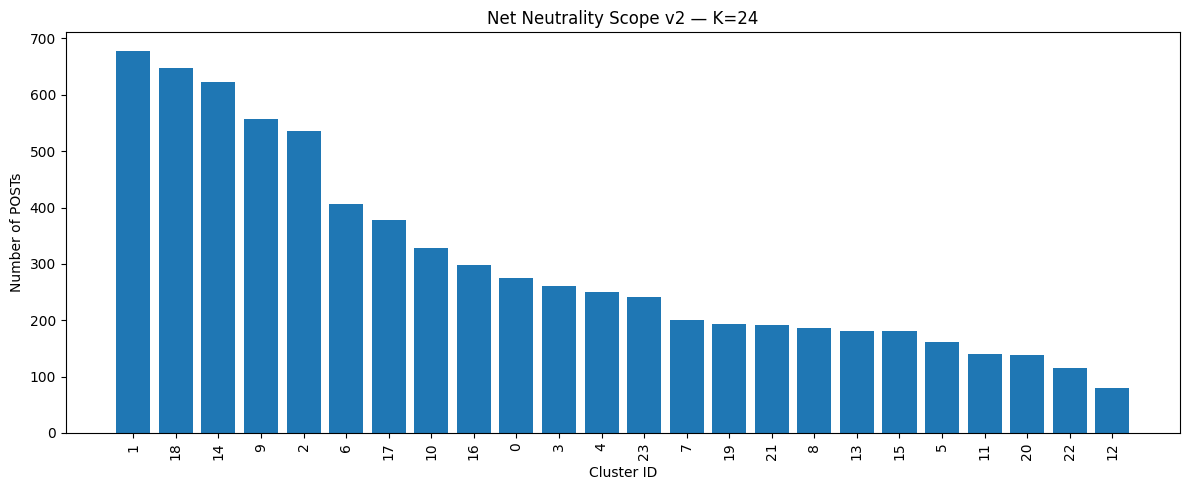

Assigned POSTs: 7244
Cluster count: 24
Labeling samples: 360


,cluster_id,cluster_size,first_post,last_post,fraction
1,1,677,2014-01-14 18:33:04+00:00,2020-11-25 14:21:13+00:00,0.093457
18,18,648,2014-01-15 20:28:06+00:00,2020-10-22 19:23:17+00:00,0.089453
14,14,623,2014-01-15 19:24:27+00:00,2020-08-30 01:04:01+00:00,0.086002
9,9,557,2014-01-14 16:05:45+00:00,2020-12-03 14:28:20+00:00,0.076891
2,2,535,2014-01-10 02:05:10+00:00,2020-10-27 19:55:24+00:00,0.073854
6,6,406,2014-01-14 15:48:18+00:00,2020-02-25 04:50:26+00:00,0.056046
17,17,377,2014-01-14 19:30:33+00:00,2020-10-26 15:41:21+00:00,0.052043
10,10,328,2014-01-15 17:12:55+00:00,2020-09-30 13:40:20+00:00,0.045279
16,16,298,2014-01-15 08:32:07+00:00,2020-07-22 20:41:38+00:00,0.041137
0,0,275,2014-01-15 10:03:38+00:00,2020-10-12 17:01:36+00:00,0.037962


,post_id,cluster_id,sample_group,centroid_similarity,content,publish_datetime_utc
0,829fe7f0-b21b-55a0-a492-0ba4c4b8c40c,0,CORE,0.789124,Cable companies 'stunned' by Obama's 'extreme'...,2014-11-10 20:18:04+00:00
1,0f5ddc02-a2fa-55c7-bec4-5cd0d19f269e,0,CORE,0.820400,"President Obama calls for net neutrality, dema...",2014-11-17 12:04:38+00:00
2,af89b8c6-765e-591d-9c6d-42ae2179489e,0,CORE,0.842460,Trump Is in for a Fight in Repealing Net Neutr...,2017-04-02 12:20:21+00:00
3,a3c4c862-c49e-5ebf-890f-54ebdb0ff0b7,0,CORE,0.894510,The future of net neutrality in Trump’s America,2017-04-05 17:23:58+00:00
4,03b97079-eb83-58e5-9813-e9a0a0239a61,0,CORE,0.803875,Net Neutrality Repeal: Donald Trump could now ...,2017-11-22 17:38:02+00:00
5,76e78f53-4fa1-50e7-a787-41e6df555226,0,MIDDLE,0.724033,Wow. Didn't know Ted Cruz could be so honest. ...,2014-11-10 19:40:04+00:00
6,5ddca7fd-db07-559c-82f9-281c9f0270f7,0,MIDDLE,0.758544,Sign Obama's Petition for Net-Neutrality - you...,2014-11-11 19:31:52+00:00
7,2ddc3330-56d3-5b27-86b3-649f4deb89d0,0,MIDDLE,0.741810,What fox thinks about Net Neutrality.,2015-02-27 03:35:48+00:00
8,07db805f-0ce3-5cb5-aa67-b6cbcc206155,0,MIDDLE,0.789048,Just got a response from Senator Ron Johnson a...,2016-03-02 02:50:54+00:00
9,47b6e013-6571-5cad-9220-049258774b0a,0,MIDDLE,0.776960,Trump Picks Staunch Opponents of Net Neutralit...,2016-11-21 23:38:37+00:00



CELL 24: PASS | CANDIDATE EXPORT COMPLETED


In [12]:
print("========== CELL 24 | EXPORT V2 RESULTS ==========")

assignments_v2 = pd.DataFrame({
    "post_id": ids_v2,
    "cluster_id": candidate_labels.astype(int)
})

assignments_v2 = assignments_v2.merge(
    scope_v2[
        ["post_id", "publish_datetime_utc"]
    ],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert len(assignments_v2) == 7244
assert assignments_v2["post_id"].is_unique
assert assignments_v2["cluster_id"].nunique() == CANDIDATE_K
assert assignments_v2["publish_datetime_utc"].notna().all()

stats_v2 = (
    assignments_v2.groupby("cluster_id")
    .agg(
        cluster_size=("post_id", "size"),
        first_post=("publish_datetime_utc", "min"),
        last_post=("publish_datetime_utc", "max")
    )
    .reset_index()
    .sort_values("cluster_size", ascending=False)
)

stats_v2["fraction"] = (
    stats_v2["cluster_size"] / len(assignments_v2)
)

centers_v2 = normalize(
    candidate_model.cluster_centers_.astype(np.float32)
)

sample_rows = []

for cid in sorted(np.unique(candidate_labels)):

    loc = np.flatnonzero(candidate_labels == cid)

    sim = X_v2[loc] @ centers_v2[cid]
    ordered = loc[np.argsort(-sim, kind="stable")]

    # Chia vùng theo độ tương đồng centroid
    n = len(ordered)

    zones = {
        "CORE": ordered[:n // 3],
        "MIDDLE": ordered[n // 3:2*n // 3],
        "EDGE": ordered[2*n // 3:]
    }

    for group, positions in zones.items():

        if not len(positions):
            continue

        chosen = positions[
            np.linspace(
                0,
                len(positions) - 1,
                min(5, len(positions)),
                dtype=int
            )
        ]

        for pos in np.unique(chosen):
            sample_rows.append({
                "post_id": ids_v2[pos],
                "cluster_id": int(cid),
                "sample_group": group,
                "centroid_similarity": float(
                    X_v2[pos] @ centers_v2[cid]
                )
            })

samples_v2 = pd.DataFrame(sample_rows)

samples_v2 = samples_v2.merge(
    scope_v2[
        ["post_id", "content", "publish_datetime_utc"]
    ],
    on="post_id",
    how="left",
    validate="one_to_one"
)

assert samples_v2["content"].notna().all()
assert set(samples_v2.cluster_id) == set(
    assignments_v2.cluster_id
)

assignments_v2.to_csv(
    OUT_V2 / "cluster_assignments.csv",
    index=False
)

stats_v2.to_csv(
    OUT_V2 / "cluster_statistics.csv",
    index=False
)

samples_v2.to_csv(
    OUT_V2 / "cluster_labeling_samples.csv",
    index=False
)

# Lưu mô hình của chính run này
joblib.dump(
    candidate_model,
    OUT_V2 / "candidate_clustering_model.joblib"
)

# Không tải model từ nguồn không tin cậy
loaded_model = joblib.load(
    OUT_V2 / "candidate_clustering_model.joblib"
)

assert np.array_equal(
    loaded_model.predict(X_v2),
    candidate_labels
)

plt.figure(figsize=(12, 5))

plt.bar(
    stats_v2.cluster_id.astype(str),
    stats_v2.cluster_size
)

plt.title(
    f"Net Neutrality Scope v2 — K={CANDIDATE_K}"
)
plt.xlabel("Cluster ID")
plt.ylabel("Number of POSTs")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    OUT_V2 / "cluster_sizes.png",
    dpi=180
)

plt.show()

print("Assigned POSTs:", len(assignments_v2))
print("Cluster count:", len(stats_v2))
print("Labeling samples:", len(samples_v2))

display(stats_v2.head(15))
display(samples_v2.head(20))

print("\nCELL 24: PASS | CANDIDATE EXPORT COMPLETED")

In [13]:
print("========== CELL 25 | TASK 4B V2 GATE ==========")

required_files = [
    "embedding_mapping_audit.csv",
    "experiment_seed_runs.csv",
    "stability_pairwise_ari.csv",
    "experiment_comparison.csv",
    "experiment_ranking.csv",
    "cluster_assignments.csv",
    "cluster_statistics.csv",
    "cluster_labeling_samples.csv",
    "cluster_sizes.png",
    "candidate_clustering_model.joblib"
]

checks = {
    "full_embedding_mapping": bool(
        set(ids_v2) == set(scope_v2.post_id)
    ),
    "all_posts_assigned": bool(
        len(assignments_v2) == len(scope_v2)
    ),
    "unique_post_ids": bool(
        assignments_v2.post_id.is_unique
    ),
    "expected_cluster_count": bool(
        assignments_v2.cluster_id.nunique() == CANDIDATE_K
    ),
    "cluster_size_consistency": bool(
        stats_v2.cluster_size.sum() == len(scope_v2)
    ),
    "all_clusters_sampled": bool(
        set(samples_v2.cluster_id) ==
        set(assignments_v2.cluster_id)
    ),
    "all_seed_runs_completed": bool(
        len(experiments_v2) == 15
    ),
    "all_pairwise_ari_completed": bool(
        len(pairwise_v2) == 30
    ),
    "all_artifacts_saved": bool(
        all((OUT_V2 / name).is_file() for name in required_files)
    )
}

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} | {name}")

technical_pass = all(checks.values())

manifest_v2 = {
    "task": "ND3.4b",
    "run_id": "nd3_4b_scope_v2_candidate",
    "status": (
        "TECHNICAL_PASS_SCIENTIFIC_REVIEW_PENDING"
        if technical_pass else "FAIL"
    ),
    "scope_version": "v2_ai_assisted",
    "scope_post_count": int(len(scope_v2)),
    "embedding_dim": 384,
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "algorithm": "MiniBatchKMeans",
    "tested_k": K_VALUES,
    "tested_seeds": SEEDS,
    "candidate_k": CANDIDATE_K,
    "candidate_seed": CANDIDATE_SEED,
    "final_k_approved": False,
    "temporary_labels_approved": False,
    "technical_checks": checks
}

(OUT_V2 / "experiment_manifest.json").write_text(
    json.dumps(
        manifest_v2,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

assert technical_pass, "FAIL | V2 technical gate"

print("\nTASK 4B V2: TECHNICAL PASS")
print("SCIENTIFIC REVIEW: PENDING")

========== CELL 25 | TASK 4B V2 GATE ==========
PASS | full_embedding_mapping
PASS | all_posts_assigned
PASS | unique_post_ids
PASS | expected_cluster_count
PASS | cluster_size_consistency
PASS | all_clusters_sampled
PASS | all_seed_runs_completed
PASS | all_pairwise_ari_completed
PASS | all_artifacts_saved

TASK 4B V2: TECHNICAL PASS
SCIENTIFIC REVIEW: PENDING


In [14]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/NarrativeCast")
OUT = ROOT / "reports/results/nd3_task4b/v2"

LABELS = OUT / "nd3_task4b_v2_temporary_labels.csv"

assert LABELS.is_file(), "FAIL | Missing temporary labels"

labels = pd.read_csv(LABELS)
assignments = pd.read_csv(
    OUT / "cluster_assignments.csv",
    dtype={"post_id": str}
)
samples = pd.read_csv(
    OUT / "cluster_labeling_samples.csv",
    dtype={"post_id": str}
)
stats = pd.read_csv(OUT / "cluster_statistics.csv")
comparison = pd.read_csv(
    OUT / "experiment_comparison.csv"
)

print("========== CELL 26 | LABEL VALIDATION ==========")

# 1. Tính toàn vẹn assignment
assert len(assignments) == 7244
assert assignments.post_id.is_unique
assert assignments.cluster_id.nunique() == 24

# 2. Nhãn đủ và không trùng
assert len(labels) == 24
assert labels.cluster_id.is_unique
assert set(labels.cluster_id) == set(assignments.cluster_id)

# 3. Có bằng chứng thuộc đúng cluster
sample_pairs = set(zip(
    samples.cluster_id.astype(int),
    samples.post_id.astype(str)
))

invalid = []

for row in labels.itertuples():
    evidence = str(row.evidence_post_ids).split("|")

    for pid in evidence:
        if (int(row.cluster_id), pid.strip()) not in sample_pairs:
            invalid.append((row.cluster_id, pid))

assert not invalid, f"FAIL | Invalid evidence: {invalid}"

# 4. Không coi nhãn tạm là narrative gold
assert labels.is_confirmed_narrative.astype(
    str
).str.lower().eq("false").all()

# 5. Liên kết nhãn vào cluster statistics
labeled_stats = stats.merge(
    labels,
    on="cluster_id",
    how="left",
    validate="one_to_one"
)

assert len(labeled_stats) == 24
assert labeled_stats.temporary_label_en.notna().all()

labeled_stats.to_csv(
    OUT / "cluster_statistics_labeled.csv",
    index=False
)

# 6. Xuất bảng assignment có tên mô tả
named_assignments = assignments.merge(
    labels[["cluster_id", "temporary_label_en"]],
    on="cluster_id",
    how="left",
    validate="many_to_one"
)

assert len(named_assignments) == 7244

named_assignments.to_csv(
    OUT / "cluster_assignments_labeled.csv",
    index=False
)

print("PASS | 7244 unique POST assignments")
print("PASS | 24 temporary labels")
print("PASS | Evidence IDs belong to corresponding clusters")
print("PASS | No labels marked as gold narrative")
print("PASS | Labeled artifacts saved")

display(
    labeled_stats[
        [
            "cluster_id",
            "cluster_size",
            "temporary_label_en",
            "observed_cluster_character",
            "label_confidence"
        ]
    ].sort_values("cluster_id")
)

========== CELL 26 | LABEL VALIDATION ==========
PASS | 7244 unique POST assignments
PASS | 24 temporary labels
PASS | Evidence IDs belong to corresponding clusters
PASS | No labels marked as gold narrative
PASS | Labeled artifacts saved


,cluster_id,cluster_size,temporary_label_en,observed_cluster_character,label_confidence
9,0,275,US Political Leadership and Net Neutrality,MIXED,MEDIUM
0,1,677,General Net Neutrality Debate and Explainers,MIXED,LOW
4,2,535,FCC Net Neutrality Rulemaking and Votes,MIXED,MEDIUM
10,3,261,Ajit Pai and FCC Leadership Controversies,COHERENT_TOPIC,HIGH
11,4,250,Net Neutrality Petitions and Public Protests,COHERENT_TOPIC,HIGH
19,5,161,Verizon and Net Neutrality Disputes,MIXED,MEDIUM
5,6,406,ISP Policy and Net Neutrality Regulation,NOISY_MIXED,LOW
13,7,200,California Net Neutrality Law and Litigation,COHERENT_TOPIC,HIGH
16,8,187,AT&T Net Neutrality Positions and Practices,COHERENT_TOPIC,MEDIUM
3,9,557,Predicted Consequences of Net Neutrality Repeal,MIXED,LOW
